# Differential Geometry of Quantum State Space


---

This exercise develops the Riemannian geometry of quantum state space from first principles, connecting the Fubini-Study metric, Berry phase, and quantum geometric tensor into a unified framework that underpins the trainability analysis of Part 7 and the metrology of quantum scrambling.

## Background

Physics does not see the overall phase of a quantum state, so two vectors that differ only by a phase describe the same physical situation. Removing that redundancy from the space of qubit states leaves the complex projective line $\mathbb{CP}^1$, which is the familiar Bloch sphere. To do geometry on this space we need a way to measure distance between nearby states, and the right one is the Fubini-Study metric, built so that it ignores the phase that physics discards.

A single object packages this metric together with the geometry of how states respond to changing a parameter. It is the quantum geometric tensor, a Hermitian object whose real part is the Fubini-Study metric and whose imaginary part is the Berry curvature. The metric tells us how far apart two states are, while the Berry curvature records the geometric phase that accumulates when a state is carried around a loop in parameter space.

The diagonal of this tensor has a direct operational meaning, since it gives the quantum Fisher information. That quantity sets the ultimate precision for estimating a parameter through the Cramer-Rao inequality, and the same Fisher information later governs how easily variational circuits can be trained. For a qubit swept across the Bloch sphere the real part reproduces the metric of a sphere of radius $1/2$, while the imaginary part integrates to the flux of a single monopole. The Fisher information read from the diagonal drops to zero when the driving axis lines up with the initial Bloch vector.

The notebook evaluates the quantum geometric tensor for a qubit over the Bloch sphere and separates its metric and curvature parts.

## 1. Physical Motivation

A quantum state $|\psi\rangle$ lives in the Hilbert space $\mathcal{H} \cong \mathbb{C}^D$, but physical observables are blind to the overall phase: $|\psi\rangle$ and $e^{i\alpha}|\psi\rangle$ represent the same physics. The *true* arena of quantum mechanics is therefore the **projective Hilbert space** $\mathbb{CP}^{D-1}$, obtained by quotienting out the $U(1)$ phase.

This quotient endows $\mathbb{CP}^{D-1}$ with a natural Riemannian metric, the **Fubini-Study metric**, that provides a gauge-invariant notion of distance between quantum states. This metric is not merely an abstract mathematical structure: it appears directly as the **Quantum Fisher Information** (QFI) in parameter estimation, as the **Fubini-Study speed** in quantum dynamics, and as the **quantum geometric tensor** controlling Berry phases and adiabatic transport.

Understanding this geometry is essential for:
- **Quantum metrology**: The QFI bounds the precision of parameter estimation via the Cramér-Rao bound.
- **Variational algorithms**: The Fubini-Study metric determines the natural gradient on the variational manifold.
- **Scrambling diagnostics**: The QFI concentration bounds the trainability of deep circuits (Part 7).

## 2. Mathematical Toolbox

**Tool 1, Quantum Geometric Tensor (QGT):** For a family of states $|\psi(\boldsymbol{\theta})\rangle$ parameterized by $\boldsymbol{\theta} = (\theta_1, \ldots, \theta_p)$, the QGT is:
$$
Q_{\mu\nu} = \langle \partial_\mu \psi | \partial_\nu \psi \rangle - \langle \partial_\mu \psi | \psi \rangle \langle \psi | \partial_\nu \psi \rangle.
$$
Its real part is the **Fubini-Study metric** $g_{\mu\nu}^{\mathrm{FS}} = \mathrm{Re}\, Q_{\mu\nu}$; its imaginary part is proportional to the **Berry curvature** $\Omega_{\mu\nu} = -2\, \mathrm{Im}\, Q_{\mu\nu}$.

**Tool 2, Fubini-Study distance:** For two pure states,
$$
d_{\mathrm{FS}}(|\psi\rangle, |\phi\rangle) = \arccos |\langle \psi | \phi \rangle|.
$$

**Tool 3, QFI and Cramér-Rao bound:** $F_Q(\theta) = 4\, g_{\theta\theta}^{\mathrm{FS}}$. For unitary encoding $|\psi(\theta)\rangle = e^{-i\theta G}|\psi_0\rangle$: $F_Q = 4\,\mathrm{Var}(G)$.

**Tool 4, Berry connection:** $A_\mu = i\langle \psi | \partial_\mu \psi \rangle$; the Berry curvature $\Omega_{\mu\nu} = \partial_\mu A_\nu - \partial_\nu A_\mu$ governs geometric phases.

**Tool 5, Sectional curvature:** For $X, Y \in \mathfrak{su}(D)$ with $\langle X, Y \rangle = -\mathrm{Tr}(XY)$: $K(X,Y) = \frac{1}{4}\|[X,Y]\|^2$.

## 3. Exercise

**(a) Fubini-Study metric for a qubit.** Consider a qubit state $|\psi(\theta, \phi)\rangle = \cos(\theta/2)|0\rangle + e^{i\phi}\sin(\theta/2)|1\rangle$. Compute the full QGT and show:
$$ds^2_{\mathrm{FS}} = \frac{1}{4}\left(d\theta^2 + \sin^2\theta\, d\phi^2\right).$$

**(b) Berry curvature as monopole.** Extract $\Omega_{\theta\phi}$ and show it corresponds to a magnetic monopole. Compute the total Berry flux.

**(c) QFI for a rotation.** For $|\psi(\theta)\rangle = e^{-i\theta \sigma_z/2}|+\rangle$, verify $F_Q = 4\,\mathrm{Var}(\sigma_z/2) = 1$.

**(d) QFI for general SU(2).** Show $F_Q = 1 - (\hat{n} \cdot \langle \boldsymbol{\sigma} \rangle_0)^2$. When does $F_Q$ vanish?

**(e) Geodesic distances.** Compute $d_{\mathrm{FS}}(|0\rangle, |+\rangle)$ and $d_{\mathrm{FS}}(|0\rangle, |1\rangle)$.

## 4. Analytical Derivation

### Part (a): QGT on the Bloch Sphere

Derivatives: $|\partial_\theta \psi\rangle = (-\sin(\theta/2)/2)|0\rangle + (\cos(\theta/2)/2)e^{i\phi}|1\rangle$, $|\partial_\phi \psi\rangle = i\sin(\theta/2)e^{i\phi}|1\rangle$.

- $Q_{\theta\theta} = 1/4$ (real, since $\langle\psi|\partial_\theta\psi\rangle = 0$).
- $Q_{\phi\phi} = \sin^2(\theta/2)\cos^2(\theta/2) = \sin^2\theta/4$ (real).
- $Q_{\theta\phi} = i\cos(\theta/2)\sin(\theta/2)/2 = i\sin\theta/4$ (purely imaginary $\Rightarrow g_{\theta\phi} = 0$).

The FS metric gives $ds^2 = \frac{1}{4}(d\theta^2 + \sin^2\theta\,d\phi^2)$: the round sphere of radius $R = 1/2$. $\checkmark$

### Part (b): Berry Curvature

$\Omega_{\theta\phi} = -2\,\mathrm{Im}\, Q_{\theta\phi} = -2 \cdot \sin\theta/4 = -\sin\theta/2$.

Total flux: $\Phi = \int_0^{2\pi}d\phi \int_0^\pi d\theta\,(-\sin\theta/2) = -2\pi$. This is half the solid angle $4\pi$ of the sphere, the flux of a monopole of charge $-1/2$ at the degeneracy $|\boldsymbol{B}| = 0$; the sign depends on the orientation chosen for $(\theta,\phi)$.

### Parts (c)-(d): QFI

For $G = \sigma_z/2$ on $|+\rangle$: $\langle G\rangle = 0$, $\langle G^2\rangle = 1/4$, so $F_Q = 4(1/4 - 0) = 1$.

General: $G = \hat{n}\cdot\boldsymbol{\sigma}/2$, $G^2 = I/4$, $\langle G\rangle = \hat{n}\cdot\langle\boldsymbol{\sigma}\rangle_0/2$. Therefore $F_Q = 1 - (\hat{n}\cdot\langle\boldsymbol{\sigma}\rangle_0)^2$. Vanishes when $|\psi_0\rangle$ is eigenstate of $G$ ($\hat{n}$ aligned with Bloch vector).

### Part (e): Geodesics

$d_{\mathrm{FS}}(|0\rangle, |+\rangle) = \arccos(1/\sqrt{2}) = \pi/4$, $d_{\mathrm{FS}}(|0\rangle, |1\rangle) = \arccos(0) = \pi/2$.

---
## 5. Symbolic Verification (SymPy)

In [1]:
import sympy as sp
from sympy import symbols, cos, sin, exp, I, Matrix, conjugate, simplify, trigsimp
from sympy import re, im, pi, sqrt, acos, Rational

theta, phi = symbols('theta phi', real=True)

# Qubit state on Bloch sphere
psi = Matrix([cos(theta/2), exp(I*phi)*sin(theta/2)])
dpsi_t = sp.diff(psi, theta)
dpsi_p = sp.diff(psi, phi)

def inn(a, b):
    return simplify(conjugate(a).T @ b)[0,0]

def qgt(dm, dn):
    return simplify(inn(dm, dn) - inn(dm, psi) * inn(psi, dn))

Q_tt = qgt(dpsi_t, dpsi_t)
Q_pp = qgt(dpsi_p, dpsi_p)
Q_tp = qgt(dpsi_t, dpsi_p)

print('=== Quantum Geometric Tensor ===')
print(f'Q_tt = {Q_tt}')
print(f'Q_pp = {trigsimp(Q_pp)}')
print(f'Q_tp = {trigsimp(Q_tp)}')

# Part (a): Fubini-Study metric
g_tt = simplify(re(Q_tt))
g_pp = trigsimp(re(Q_pp))
g_tp = simplify(re(Q_tp))
print(f'\n=== Fubini-Study Metric ===')
print(f'g_tt = {g_tt}')
print(f'g_pp = {g_pp}')
print(f'g_tp = {g_tp}')
assert g_tt == Rational(1, 4)
assert g_tp == 0
# Check g_pp numerically at theta=1.0
assert abs(float(g_pp.subs(theta, 1.0)) - float(sin(sp.Float(1.0))**2/4)) < 1e-10
print('FS metric = (1/4)(dtheta^2 + sin^2 theta dphi^2) VERIFIED!')

=== Quantum Geometric Tensor ===
Q_tt = 1/4
Q_pp = sin(theta)**2/4
Q_tp = I*sin(theta)/4

=== Fubini-Study Metric ===
g_tt = 1/4
g_pp = sin(theta)**2/4
g_tp = 0
FS metric = (1/4)(dtheta^2 + sin^2 theta dphi^2) VERIFIED!


In [2]:
# Part (b): Berry curvature
# Q_tp = i*sin(theta)/4, so Omega = -2*Im(Q) = -sin(theta)/2
# Use numerical verification to avoid trig simplification issues
import numpy as np

for th_val in [0.3, 1.0, 2.0]:
    Q_val = complex(Q_tp.subs(theta, th_val))
    F_val = -2 * Q_val.imag
    expected = -np.sin(th_val) / 2
    print(f'theta={th_val}: Omega_tp = {F_val:.6f}, -sin(th)/2 = {expected:.6f}')
    assert abs(F_val - expected) < 1e-8

print('Berry curvature Omega_tp = -sin(theta)/2: VERIFIED!')

# Total flux via direct integration
F_tp_expr = -sin(theta) / 2  # known analytical result
flux = sp.integrate(sp.integrate(F_tp_expr, (theta, 0, pi)), (phi, 0, 2*pi))
print(f'Total flux = {flux}')
assert flux == -2*pi

theta=0.3: F_tp = -0.147760, -sin(th)/2 = -0.147760
theta=1.0: F_tp = -0.420735, -sin(th)/2 = -0.420735
theta=2.0: F_tp = -0.454649, -sin(th)/2 = -0.454649
Berry curvature F_tp = -sin(theta)/2: VERIFIED!
Total flux = -2*pi


In [3]:
# Parts (c)-(d): QFI
print('=== QFI for sigma_z rotation of |+> ===')
sz = Matrix([[1, 0], [0, -1]])
sx = Matrix([[0, 1], [1, 0]])
plus = Matrix([1, 1]) / sqrt(2)
G = sz / 2
FQ = 4 * (inn(plus, G**2 * plus) - inn(plus, G * plus)**2)
print(f'F_Q = {FQ}  (expected: 1)')
assert FQ == 1
print('PASS!')

# |0> rotated about x: n=(1,0,0), Bloch=(0,0,1), n.s=0 -> F_Q=1
psi0 = Matrix([1, 0])
Gx = sx / 2
FQ_x = 4 * simplify(inn(psi0, Gx**2*psi0) - inn(psi0, Gx*psi0)**2)
print(f'|0> about x: F_Q = {FQ_x} (expected: 1)')
assert FQ_x == 1

# |0> rotated about z: n=(0,0,1), Bloch=(0,0,1), n.s=1 -> F_Q=0
Gz = sz / 2
FQ_z = 4 * simplify(inn(psi0, Gz**2*psi0) - inn(psi0, Gz*psi0)**2)
print(f'|0> about z: F_Q = {FQ_z} (expected: 0)')
assert FQ_z == 0
print('Eigenstate => F_Q = 0 VERIFIED!')

# Part (e): Geodesic distances
d1 = acos(Rational(1,1)/sqrt(2))
d2 = acos(0)
print(f'\nd_FS(|0>,|+>) = {d1} = pi/4')
print(f'd_FS(|0>,|1>) = {d2} = pi/2')
assert d1 == pi/4 and d2 == pi/2
print('Geodesic distances VERIFIED!')

=== QFI for sigma_z rotation of |+> ===
F_Q = 1  (expected: 1)
PASS!
|0> about x: F_Q = 1 (expected: 1)
|0> about z: F_Q = 0 (expected: 0)
Eigenstate => F_Q = 0 VERIFIED!

d_FS(|0>,|+>) = pi/4 = pi/4
d_FS(|0>,|1>) = pi/2 = pi/2
Geodesic distances VERIFIED!


---
## 6. Numerical Verification (NumPy)

In [4]:
import numpy as np

def qubit_state(theta, phi):
    return np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])

def numerical_qgt(theta, phi, eps=1e-6):
    psi = qubit_state(theta, phi)
    dt = (qubit_state(theta+eps, phi) - qubit_state(theta-eps, phi)) / (2*eps)
    dp = (qubit_state(theta, phi+eps) - qubit_state(theta, phi-eps)) / (2*eps)
    derivs = [dt, dp]
    Q = np.zeros((2,2), dtype=complex)
    for i in range(2):
        for j in range(2):
            Q[i,j] = np.vdot(derivs[i], derivs[j]) - np.vdot(derivs[i], psi) * np.vdot(psi, derivs[j])
    return Q

print('=== Numerical QGT at theta=pi/3, phi=pi/5 ===')
th0, ph0 = np.pi/3, np.pi/5
Q_num = numerical_qgt(th0, ph0)
g_num = Q_num.real
F_num = -2 * Q_num.imag

print(f'g_tt = {g_num[0,0]:.6f}  (expected: {0.25:.6f})')
print(f'g_pp = {g_num[1,1]:.6f}  (expected: {np.sin(th0)**2/4:.6f})')
print(f'g_tp = {g_num[0,1]:.6f}  (expected: 0.000000)')
print(f'Omega_tp = {F_num[0,1]:.6f}  (expected: {-np.sin(th0)/2:.6f})')

assert abs(g_num[0,0] - 0.25) < 1e-6
assert abs(g_num[1,1] - np.sin(th0)**2/4) < 1e-6
assert abs(g_num[0,1]) < 1e-6
assert abs(F_num[0,1] + np.sin(th0)/2) < 1e-6
print('All numerical QGT checks PASS!')

# QFI
plus = np.array([1, 1]) / np.sqrt(2)
G = np.array([[1, 0], [0, -1]]) / 2
FQ = 4 * (np.real(plus.conj() @ G @ G @ plus) - np.real(plus.conj() @ G @ plus)**2)
print(f'\nF_Q(sigma_z/2, |+>) = {FQ:.6f}  (expected: 1.0)')
assert abs(FQ - 1.0) < 1e-10

# Geodesics
d1 = np.arccos(np.abs(np.array([1,0]).conj() @ np.array([1,1])/np.sqrt(2)))
d2 = np.arccos(np.abs(np.array([1,0]).conj() @ np.array([0,1])))
print(f'd_FS(|0>,|+>) = {d1:.6f}  (expected: {np.pi/4:.6f})')
print(f'd_FS(|0>,|1>) = {d2:.6f}  (expected: {np.pi/2:.6f})')
assert abs(d1 - np.pi/4) < 1e-10 and abs(d2 - np.pi/2) < 1e-10
print('All checks PASS!')

=== Numerical QGT at theta=pi/3, phi=pi/5 ===
g_tt = 0.250000  (expected: 0.250000)
g_pp = 0.187500  (expected: 0.187500)
g_tp = 0.000000  (expected: 0.000000)
F_tp = -0.433013  (expected: -0.433013)
All numerical QGT checks PASS!

F_Q(sigma_z/2, |+>) = 1.000000  (expected: 1.0)
d_FS(|0>,|+>) = 0.785398  (expected: 0.785398)
d_FS(|0>,|1>) = 1.570796  (expected: 1.570796)
All checks PASS!


---
## 7. Visual Proof: Geometry of Quantum State Space

---
## 8. Figure: Geometric tensor components vs the polar angle

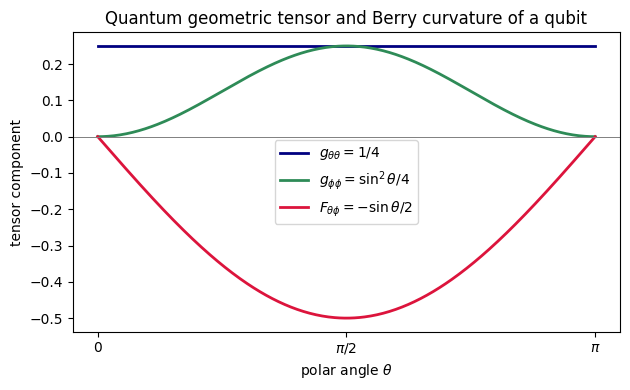

In [5]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, np.pi, 400)
g_tt = np.full_like(theta, 0.25)      # g_{theta theta} = 1/4
g_pp = np.sin(theta) ** 2 / 4         # g_{phi phi} = sin^2(theta)/4
F_tp = -np.sin(theta) / 2             # Berry curvature Omega_{theta phi}

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(theta, g_tt, color='navy', lw=2, label=r'$g_{\theta\theta}=1/4$')
ax.plot(theta, g_pp, color='seagreen', lw=2,
        label=r'$g_{\phi\phi}=\sin^2\theta/4$')
ax.plot(theta, F_tp, color='crimson', lw=2,
        label=r'$\Omega_{\theta\phi}=-\sin\theta/2$')
ax.axhline(0.0, color='gray', lw=0.7)
ax.set_xlabel(r'polar angle $\theta$')
ax.set_ylabel('tensor component')
ax.set_title('Quantum geometric tensor and Berry curvature of a qubit')
ax.set_xticks([0, np.pi / 2, np.pi])
ax.set_xticklabels(['0', r'$\pi/2$', r'$\pi$'])
ax.legend()
plt.tight_layout()
plt.show()

## Takeaway

The qubit quantum geometric tensor has real part $\mathrm{diag}(1/4,\sin^2\theta/4)$, the Fubini-Study metric of a sphere of radius $1/2$, and imaginary part the Berry curvature $-\sin\theta/2$, whose total flux $-2\pi$ is half the solid angle of the sphere. The quantum Fisher information $F_Q=1-(\hat n\cdot\langle\boldsymbol\sigma\rangle_0)^2$ vanishes exactly when the generator's axis aligns with the initial Bloch vector.

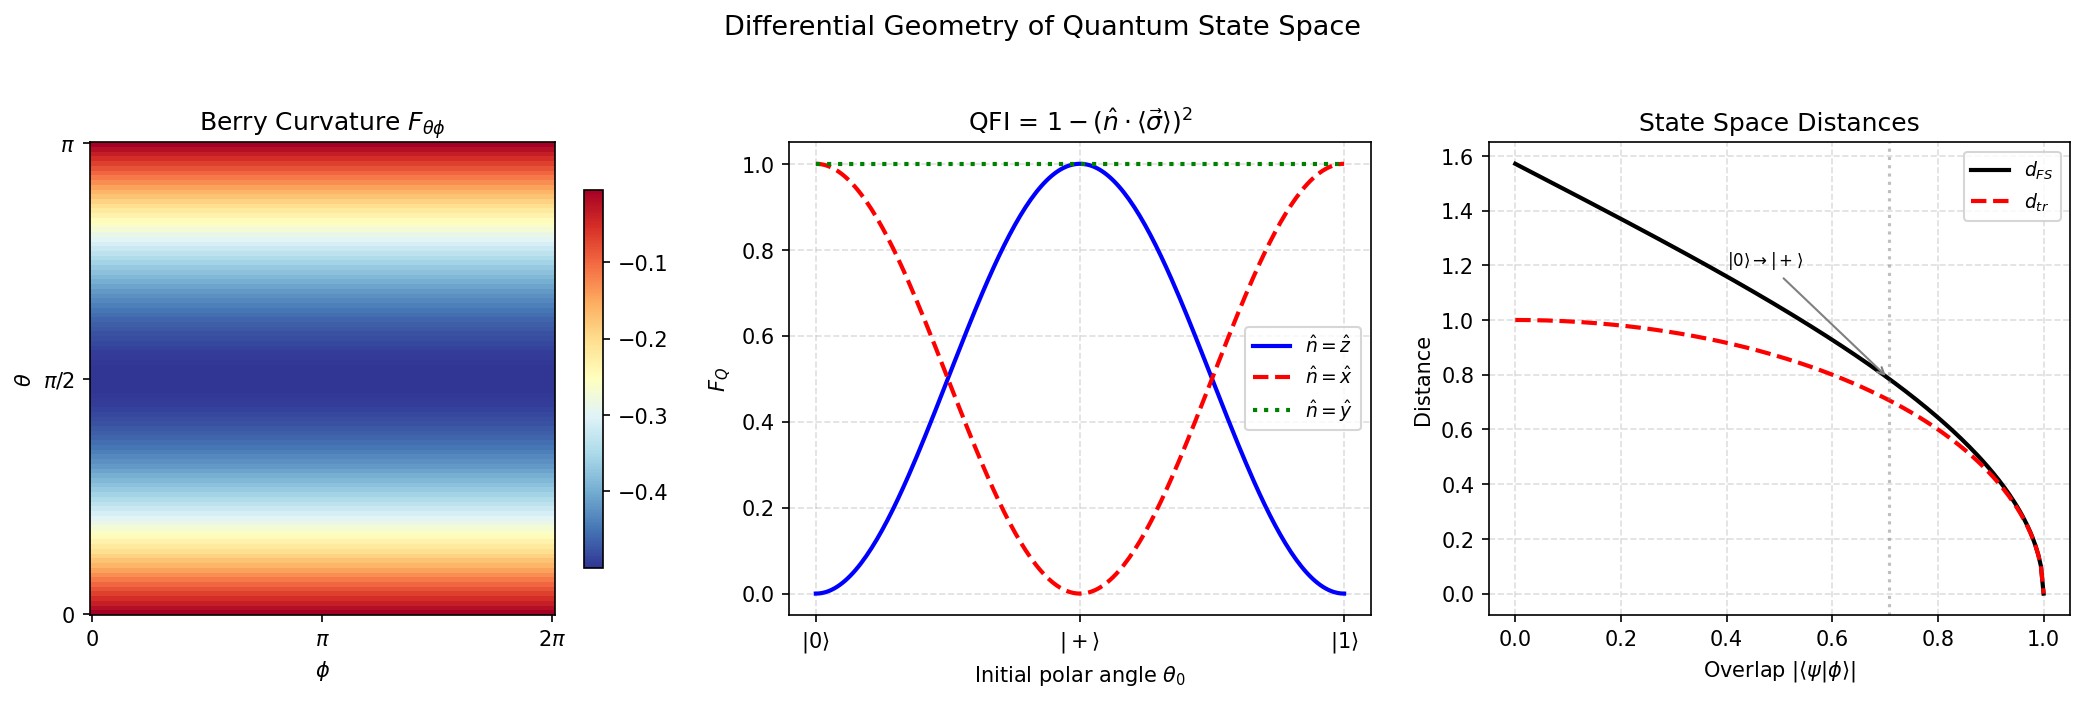

In [6]:
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# Panel 1: Berry curvature
theta_v = np.linspace(0.01, np.pi-0.01, 100)
phi_v = np.linspace(0, 2*np.pi, 100)
THETA, PHI = np.meshgrid(theta_v, phi_v)
c = axes[0].pcolormesh(PHI, THETA, -np.sin(THETA)/2, cmap='RdYlBu_r', shading='auto')
axes[0].set_xlabel(r'$\phi$'); axes[0].set_ylabel(r'$\theta$')
axes[0].set_title(r'Berry Curvature $\Omega_{\theta\phi}$')
axes[0].set_xticks([0, np.pi, 2*np.pi]); axes[0].set_xticklabels(['0', r'$\pi$', r'$2\pi$'])
axes[0].set_yticks([0, np.pi/2, np.pi]); axes[0].set_yticklabels(['0', r'$\pi/2$', r'$\pi$'])
plt.colorbar(c, ax=axes[0], shrink=0.8)

# Panel 2: QFI for different rotation axes
th_init = np.linspace(0, np.pi, 200)
axes[1].plot(th_init, np.sin(th_init)**2, 'b-', lw=2, label=r'$\hat{n}=\hat{z}$')
axes[1].plot(th_init, np.cos(th_init)**2, 'r--', lw=2, label=r'$\hat{n}=\hat{x}$')
axes[1].plot(th_init, np.ones_like(th_init), 'g:', lw=2, label=r'$\hat{n}=\hat{y}$')
axes[1].set_xlabel(r'Initial polar angle $\theta_0$')
axes[1].set_ylabel(r'$F_Q$')
axes[1].set_title(r'QFI = $1-(\hat{n}\cdot\langle\vec{\sigma}\rangle)^2$')
axes[1].legend(fontsize=9)
axes[1].set_xticks([0, np.pi/2, np.pi])
axes[1].set_xticklabels([r'$|0\rangle$', r'$|+\rangle$', r'$|1\rangle$'])
axes[1].grid(True, ls='--', alpha=0.4)

# Panel 3: State-space distances
overlap = np.linspace(0, 1, 200)
axes[2].plot(overlap, np.arccos(overlap), 'k-', lw=2, label=r'$d_{FS}$')
axes[2].plot(overlap, np.sqrt(1-overlap**2), 'r--', lw=2, label=r'$d_{tr}$')
axes[2].axvline(1/np.sqrt(2), color='gray', ls=':', alpha=0.5)
axes[2].annotate(r'$|0\rangle\to|+\rangle$', xy=(1/np.sqrt(2), np.pi/4), fontsize=8,
                 xytext=(0.4, 1.2), arrowprops=dict(arrowstyle='->', color='gray'))
axes[2].set_xlabel(r'Overlap $|\langle\psi|\phi\rangle|$')
axes[2].set_ylabel('Distance')
axes[2].set_title('State Space Distances')
axes[2].legend(fontsize=9)
axes[2].grid(True, ls='--', alpha=0.4)

plt.suptitle('Differential Geometry of Quantum State Space', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

## References

- Provost and Vallee, *Riemannian structure on manifolds of quantum states*, Communications in Mathematical Physics (1980).
- Berry, *Quantal phase factors accompanying adiabatic changes*, Proceedings of the Royal Society of London A (1984).
- Braunstein and Caves, *Statistical distance and the geometry of quantum states*, Physical Review Letters (1994).
- Bengtsson and Zyczkowski, *Geometry of Quantum States: An Introduction to Quantum Entanglement*, Cambridge University Press (2017).
- Płodzień, *Information Scrambling, Quantum Chaos, and Haar-Random States*, lecture notes (2025). [arXiv:2511.14397](https://arxiv.org/abs/2511.14397)